# Кого пригласить вернуться в «Зерно»

Исходная версия аудита 2026-11-16 до исправлений курса. Самостоятельный проект после главы 6. Автор: агент-ученик. Использованы только ученические материалы и учебные CSV. Отправок гостям нет.


## Решение и план до просмотра теста

Один объект — один гость на1октября2026. Признаки — только доступная на эту дату история; цель — отсутствие визитов в `[2026-10-01,2026-11-30)`. Метка созревает30ноября. В пакете это ретроспективный учебный пример; на календарную дату16ноября такие метки еще не были бы доступны. Рабочий список строю на отдельном свежем срезе1декабря, а не на устаревшей октябрьской истории.

План: осмотр и временная доступность → пропуски → заранее отложенный тест25% → выбор глубины и семейства на пятикратной валидации оставшихся75% → один финальный блок оценки → список по свежим признакам.

Критерий фиксирую сейчас: максимальная средняя accuracy на общих фолдах; при точном равенстве — более простая модель в порядке перебора (неглубокое дерево, затем лес, затем логрегрессия). Отдельно проверяю соответствие бюджетной задаче по доле уходов в топ10%; если бизнес подтвердит, что именно ранжирование — главная цель, в следующей версии заранее выберу критерий ранжирования. Не меняю критерий после открытия теста. Сравнение — «никто не уйдет», правило45дней и равный бюджет топ10% по давности. Риск оттока не равен эффекту бонуса: для решения о запуске нужен A/B-тест и стоимость удержания.

In [1]:
from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.base import clone

RANDOM_STATE = 42
MODEL_RANDOM_STATE = 0
DATA = Path("data")
OUTPUT = Path("project-output")
OUTPUT.mkdir(exist_ok=True)


Подключены библиотеки и зафиксированы воспроизводимые зерна разбиения и моделей. Все данные читаются относительно блокнота; результаты сохраняются отдельно от исходных таблиц.

## Осмотр и происхождение признаков

In [2]:
g = pd.read_csv(DATA / "guests_churn.csv")
dates = pd.read_csv(DATA / "guests_churn_dates.csv")
current = pd.read_csv(DATA / "guests_current.csv")
assert g.guest_id.is_unique and dates.guest_id.is_unique and current.guest_id.is_unique
assert set(g.guest_id) == set(dates.guest_id)
print("Размеры:", g.shape, current.shape)
print("Доля ухода:", g.churned.mean())
print("Пропуски:", g.isna().sum().to_dict())
print(dates.drop(columns="guest_id").drop_duplicates().to_string(index=False))
print("Свежие срезы:", current.snapshot_date.unique())
print(g.describe(include="all").T.to_string())


Размеры: (2400, 13) (2400, 12)
Доля ухода: 0.22291666666666668
Пропуски: {'guest_id': 0, 'city': 0, 'tenure_months': 0, 'app': 0, 'visits_90d': 0, 'days_since_last': 0, 'avg_check': 144, 'delivery_share': 0, 'fav_category': 0, 'promo_used': 0, 'complaints': 0, 'card_blocked': 0, 'churned': 0}
snapshot_date target_start target_end_exclusive target_available_at card_blocked_available_at
   2026-10-01   2026-10-01           2026-11-30          2026-11-30                2026-11-30
Свежие срезы: <ArrowStringArray>
['2026-12-01']
Length: 1, dtype: str
                  count unique      top  freq        mean        std    min     25%    50%    75%    max
guest_id           2400   2400  G-10001     1         NaN        NaN    NaN     NaN    NaN    NaN    NaN
city               2400      4   Казань   824         NaN        NaN    NaN     NaN    NaN    NaN    NaN
tenure_months    2400.0    NaN      NaN   NaN     17.9775  14.339578    1.0     8.0   14.0   23.0   60.0
app              2400.0    N

Гость встречается один раз, поэтому обычное стратифицированное разбиение по гостям здесь не смешивает повторные заказы. Для нескольких временных срезов потребовалась бы проверка по времени. Результаты из одного октябрьского среза не доказывают качество на декабре.

`card_blocked_available_at` равен дате доступности ответа: `card_blocked` нельзя брать в признаки1октября. Удаляю его по происхождению до моделирования, не по качеству на тесте. `guest_id` нужен только для выдачи списка. Даты окна — служебный контроль, не признаки.

## Пропуски, признаки и нетронутый тест

In [3]:
features = ["city", "tenure_months", "app", "visits_90d", "days_since_last", "avg_check", "delivery_share", "fav_category", "promo_used", "complaints"]
assert (g.loc[g.avg_check.isna(), "visits_90d"] == 0).all()
assert (current.loc[current.avg_check.isna(), "visits_90d"] == 0).all()


def prepare(frame, columns=None):
    x = frame[features].copy()
    x["no_visits"] = (x.visits_90d == 0).astype(int)
    x["avg_check"] = x.avg_check.fillna(0)
    x = pd.get_dummies(x, dtype=int)
    if columns is not None:
        x = x.reindex(columns=columns, fill_value=0)
    return x


dev, test = train_test_split(g, test_size=.25, random_state=RANDOM_STATE, stratify=g.churned)
assert set(dev.guest_id).isdisjoint(test.guest_id)
print("Количество гостей development/test:", len(dev), len(test))
print("Плановый бюджет в тесте:", int(len(test) * .1))
print("Признаки:", prepare(dev).columns.tolist())


Количество гостей development/test: 1800 600
Плановый бюджет в тесте: 60
Признаки: ['tenure_months', 'app', 'visits_90d', 'days_since_last', 'avg_check', 'delivery_share', 'promo_used', 'complaints', 'no_visits', 'city_Казань', 'city_Пермь', 'city_Тюмень', 'city_Уфа', 'fav_category_еда', 'fav_category_кофе', 'fav_category_не кофе']


Нулевой средний чек — технический код отсутствующих покупок, а не оценка средней покупки; добавлен явный флаг `no_visits`. Этот прием не оценивает статистик по тесту. Категориальная схема создается внутри каждого обучающего фолда; незнакомые категории получают нулевые флаги. Тестовые ответы пока не используются.


## Валидация и выбор модели

In [4]:
candidates = {f"дерево {depth}": DecisionTreeClassifier(max_depth=depth, random_state=MODEL_RANDOM_STATE) for depth in range(1, 11)}
candidates["лес"] = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=MODEL_RANDOM_STATE)
candidates["логрегрессия"] = LogisticRegression(max_iter=2000)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(kf.split(dev))


def ranked_indices(frame, values, k):
    order = pd.DataFrame({"score": np.asarray(values), "guest_id": frame.guest_id.to_numpy()}, index=frame.index)
    return order.sort_values(["score", "guest_id"], ascending=[False, True]).head(k).index


rows = []
for name, estimator in candidates.items():
    scores, rates, timings = [], [], []
    for train_pos, valid_pos in folds:
        train_fold, valid_fold = dev.iloc[train_pos], dev.iloc[valid_pos]
        xtr = prepare(train_fold)
        xva = prepare(valid_fold, xtr.columns)
        model = clone(estimator)
        t0 = time.perf_counter()
        model.fit(xtr, train_fold.churned)
        timings.append(time.perf_counter() - t0)
        scores.append(accuracy_score(valid_fold.churned, model.predict(xva)))
        ids = ranked_indices(valid_fold, model.predict_proba(xva)[:, 1], int(len(valid_fold) * .1))
        rates.append(valid_fold.loc[ids, "churned"].mean())
    rows.append({"model": name, "mean": np.mean(scores), "std": np.std(scores), "top10_rate": np.mean(rates), "fit_s": np.mean(timings)})
comparison = pd.DataFrame(rows).set_index("model")
best_name = comparison["mean"].idxmax()
selected_estimator = clone(candidates[best_name])
rule_scores, base_scores, rule_rates = [], [], []
for _, valid_pos in folds:
    vf = dev.iloc[valid_pos]
    base_scores.append((vf.churned == 0).mean())
    rule_scores.append(accuracy_score(vf.churned, vf.days_since_last > 45))
    ids = ranked_indices(vf, vf.days_since_last, int(len(vf) * .1))
    rule_rates.append(vf.loc[ids, "churned"].mean())
print(comparison.round(4).to_string())
print("База CV:", np.mean(base_scores), "Правило CV:", np.mean(rule_scores), "Правило топ10%:", np.mean(rule_rates))
print("Зафиксирован победитель до теста:", best_name)
comparison.to_csv(OUTPUT / "validation.csv")
(OUTPUT / "selection-before-test.json").write_text(json.dumps({"criterion": "highest mean CV accuracy; ties follow candidate order", "winner": best_name, "CV": comparison.loc[best_name].to_dict()}, ensure_ascii=False, indent=2))


                mean     std  top10_rate   fit_s
model                                           
дерево 1      0.8050  0.0198      0.5278  0.0007
дерево 2      0.8350  0.0310      0.7556  0.0009
дерево 3      0.8406  0.0288      0.7944  0.0011
дерево 4      0.8544  0.0186      0.8333  0.0013
дерево 5      0.8439  0.0118      0.8222  0.0015
дерево 6      0.8328  0.0120      0.8056  0.0018
дерево 7      0.8372  0.0163      0.7778  0.0020
дерево 8      0.8294  0.0108      0.7222  0.0022
дерево 9      0.8283  0.0141      0.6500  0.0024
дерево 10     0.8228  0.0075      0.6444  0.0025
лес           0.8628  0.0208      0.8500  0.0660
логрегрессия  0.8583  0.0255      0.8389  0.0598
База CV: 0.7772222222222221 Правило CV: 0.8227777777777778 Правило топ10%: 0.7277777777777777
Зафиксирован победитель до теста: лес


230

Выбор завершен только по development. Числа и критерий сохранены отдельным файлом до вычисления тестовых метрик. std фолдов описывает разброс оценки, а не готовый доверительный интервал; значимость небольшого различия из него автоматически не следует.


## Единственная итоговая оценка

model                             лес
accuracy                         0.89
base_accuracy                0.776667
rule_accuracy                0.851667
budget                             60
model_top_rate                   0.95
rule_top_rate                0.866667
top_lift                     4.253731
capture                      0.425373
already_over45               0.633333
unnecessary_at_face_value           3
quiet_rate                   0.147664
quiet_model_top_rate         0.773585
quiet_days_top_rate          0.358491
                 pred   fact    n
group                            
(-0.001, 0.25]  0.062  0.035  396
(0.25, 0.5]     0.357  0.305   82
(0.5, 0.75]     0.618  0.658   76
(0.75, 1.0]     0.856  0.978   46


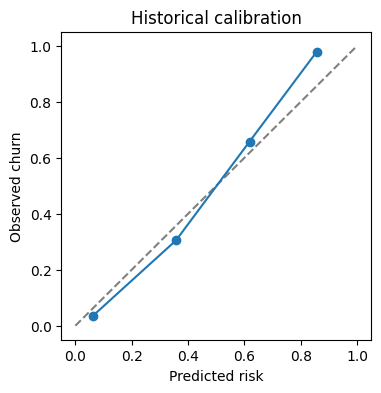

In [5]:
X_dev = prepare(dev)
X_test = prepare(test, X_dev.columns)
final_model = selected_estimator.fit(X_dev, dev.churned)
pred = final_model.predict(X_test)
risk = pd.Series(final_model.predict_proba(X_test)[:, 1], index=test.index)
k = int(len(test) * .1)
model_ids = ranked_indices(test, risk, k)
rule_ids = ranked_indices(test, test.days_since_last, k)
summary = {
    "model": best_name,
    "accuracy": accuracy_score(test.churned, pred),
    "base_accuracy": (test.churned == 0).mean(),
    "rule_accuracy": accuracy_score(test.churned, test.days_since_last > 45),
    "budget": k,
    "model_top_rate": test.loc[model_ids, "churned"].mean(),
    "rule_top_rate": test.loc[rule_ids, "churned"].mean(),
    "top_lift": test.loc[model_ids, "churned"].mean() / test.churned.mean(),
    "capture": test.loc[model_ids, "churned"].sum() / test.churned.sum(),
    "already_over45": (test.loc[model_ids, "days_since_last"] > 45).mean(),
    "unnecessary_at_face_value": int((test.loc[model_ids, "churned"] == 0).sum()),
}
quiet = test[test.days_since_last <= 45]
k_quiet = int(len(quiet) * .1)
quiet_model_ids = ranked_indices(quiet, risk.loc[quiet.index], k_quiet)
quiet_days_ids = ranked_indices(quiet, quiet.days_since_last, k_quiet)
summary["quiet_rate"] = quiet.churned.mean()
summary["quiet_model_top_rate"] = quiet.loc[quiet_model_ids, "churned"].mean()
summary["quiet_days_top_rate"] = quiet.loc[quiet_days_ids, "churned"].mean()
print(pd.Series(summary).to_string())
(OUTPUT / "test-summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
cal = pd.DataFrame({"p": risk, "fact": test.churned})
cal["group"] = pd.cut(cal.p, [0, .25, .5, .75, 1], include_lowest=True)
calibration = cal.groupby("group", observed=True).agg(pred=("p", "mean"), fact=("fact", "mean"), n=("p", "size"))
print(calibration.round(3).to_string())
fig, ax = plt.subplots(figsize=(4,4))
ax.plot([0,1],[0,1],linestyle="--",color="gray")
ax.plot(calibration.pred,calibration.fact,marker="o")
ax.set(xlabel="Predicted risk",ylabel="Observed churn",title="Historical calibration")
plt.show()


После теста модель и правило выбора не меняю. Бюджет обеих стратегий одинаков; доля уходов в топе говорит о концентрации риска, но не о том, кого бонус действительно вернет. Гости с прогнозом «не уйдет» тоже могут уйти. Вероятности нужно проверять по корзинам с учетом числа наблюдений.


## Свежий список для акции

In [6]:
X_all = prepare(g)
production_model = clone(selected_estimator).fit(X_all, g.churned)
X_current = prepare(current, X_all.columns)
current_risk = production_model.predict_proba(X_current)[:, 1]
current_k = int(len(current) * .1)
current_ids = ranked_indices(current, current_risk, current_k)
current_scores = pd.Series(current_risk, index=current.index)
send_list = current.loc[current_ids, ["snapshot_date", "guest_id", "days_since_last", "visits_90d"]].copy()
send_list["risk"] = current_scores.loc[current_ids]
send_list["reason"] = np.where(send_list.days_since_last > 45, "высокий риск, уже заметен правилу45дней", "высокий риск среди недавних посетителей")
assert len(send_list) == current_k and send_list.guest_id.is_unique
send_list.to_csv(OUTPUT / "fresh-campaign.csv", index=False)
print("Срез:", current.snapshot_date.unique(), "Бюджет:", current_k)
print(send_list.head(10).to_string(index=False))
print("Уже >45дней:", (send_list.days_since_last > 45).mean())


Срез: <ArrowStringArray>
['2026-12-01']
Length: 1, dtype: str Бюджет: 240
snapshot_date guest_id  days_since_last  visits_90d     risk                                  reason
   2026-12-01  G-11368              141           0 0.995833 высокий риск, уже заметен правилу45дней
   2026-12-01  G-11823              142           0 0.995833 высокий риск, уже заметен правилу45дней
   2026-12-01  G-11955              134           0 0.994434 высокий риск, уже заметен правилу45дней
   2026-12-01  G-12325              111           0 0.993309 высокий риск, уже заметен правилу45дней
   2026-12-01  G-12108              108           0 0.992973 высокий риск, уже заметен правилу45дней
   2026-12-01  G-11266              131           0 0.992485 высокий риск, уже заметен правилу45дней
   2026-12-01  G-11614              118           0 0.992143 высокий риск, уже заметен правилу45дней
   2026-12-01  G-11002              156           0 0.985842 высокий риск, уже заметен правилу45дней
   2026-12-01  G-

Операционный список использует декабрьские признаки, отдельные от исторического тестового списка. Финальный алгоритм фиксирован, после проверки он переобучен на всей созревшей истории. Перечень содержит ID, риск и понятную причину приоритета; это проектный список для согласования акции, автоматической рассылки нет.


## Выводы и рекомендации

Выбран лес: средняя accuracy CV86.28% при std2.08п.п. На единственном историческом тесте accuracy89.0% против77.67% у базы и85.17% у правила45дней. При равном бюджете60гостей модель выбрала57будущих ушедших (95%), а давность —52(86.67%). Лифт4.25; охват42.54% всех уходов. В списке3гостя в итоге не ушли; это не доказательство ненужности бонуса. Среди еще недавних гостей модельный топ содержит77.36%уходов против35.85%у топа по давности; все эти сравнения — описательные финальные результаты, без перенастройки по ним. Рекомендую пилот на бюджете10% с контрольной группой внутри допустимой аудитории. Критерии пилота: дополнительные визиты или маржа за60дней после вычета бонусов, отписки и жалобы как ограничения. Случайное назначение и метрики фиксируются до запуска.

Ограничения: один исторический срез, искусственный учебный пакет, возможный сдвиг сезонности на декабре, неизвестный эффект бонуса, малая группа для калибровки высоких рисков. При следующем зрелом срезе проверю качество и состав списка, соблюдая временную доступность; на16ноября октябрьские метки еще не годятся для реального обучения. Если нужны именно еще активные гости, бизнесу надо заранее определить такую аудиторию и новый критерий бюджетного отбора, а затем проверить на новом отложенном периоде.